<a href="https://colab.research.google.com/github/Oluwadara17/COHORT-RENTION-ANALYSIS/blob/main/Pima_model_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importing necessary liberies needed to analyze the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load the dataset
data = pd.read_csv(r"/content/drive/MyDrive/diabetes.csv")


In [ ]:
data.shape

(768, 9)

In [ ]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
data['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


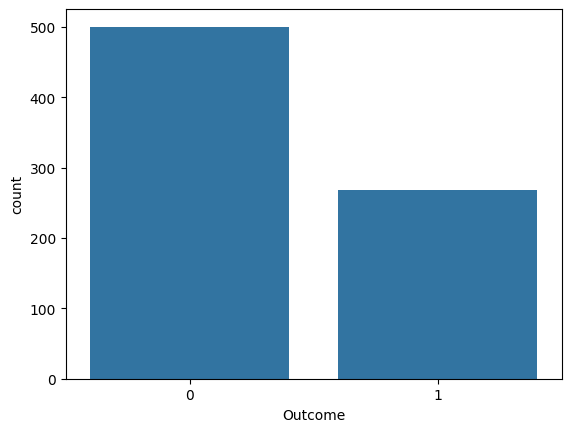

In [ ]:
sns.countplot(data=data, x=data['Outcome'])
plt.show()

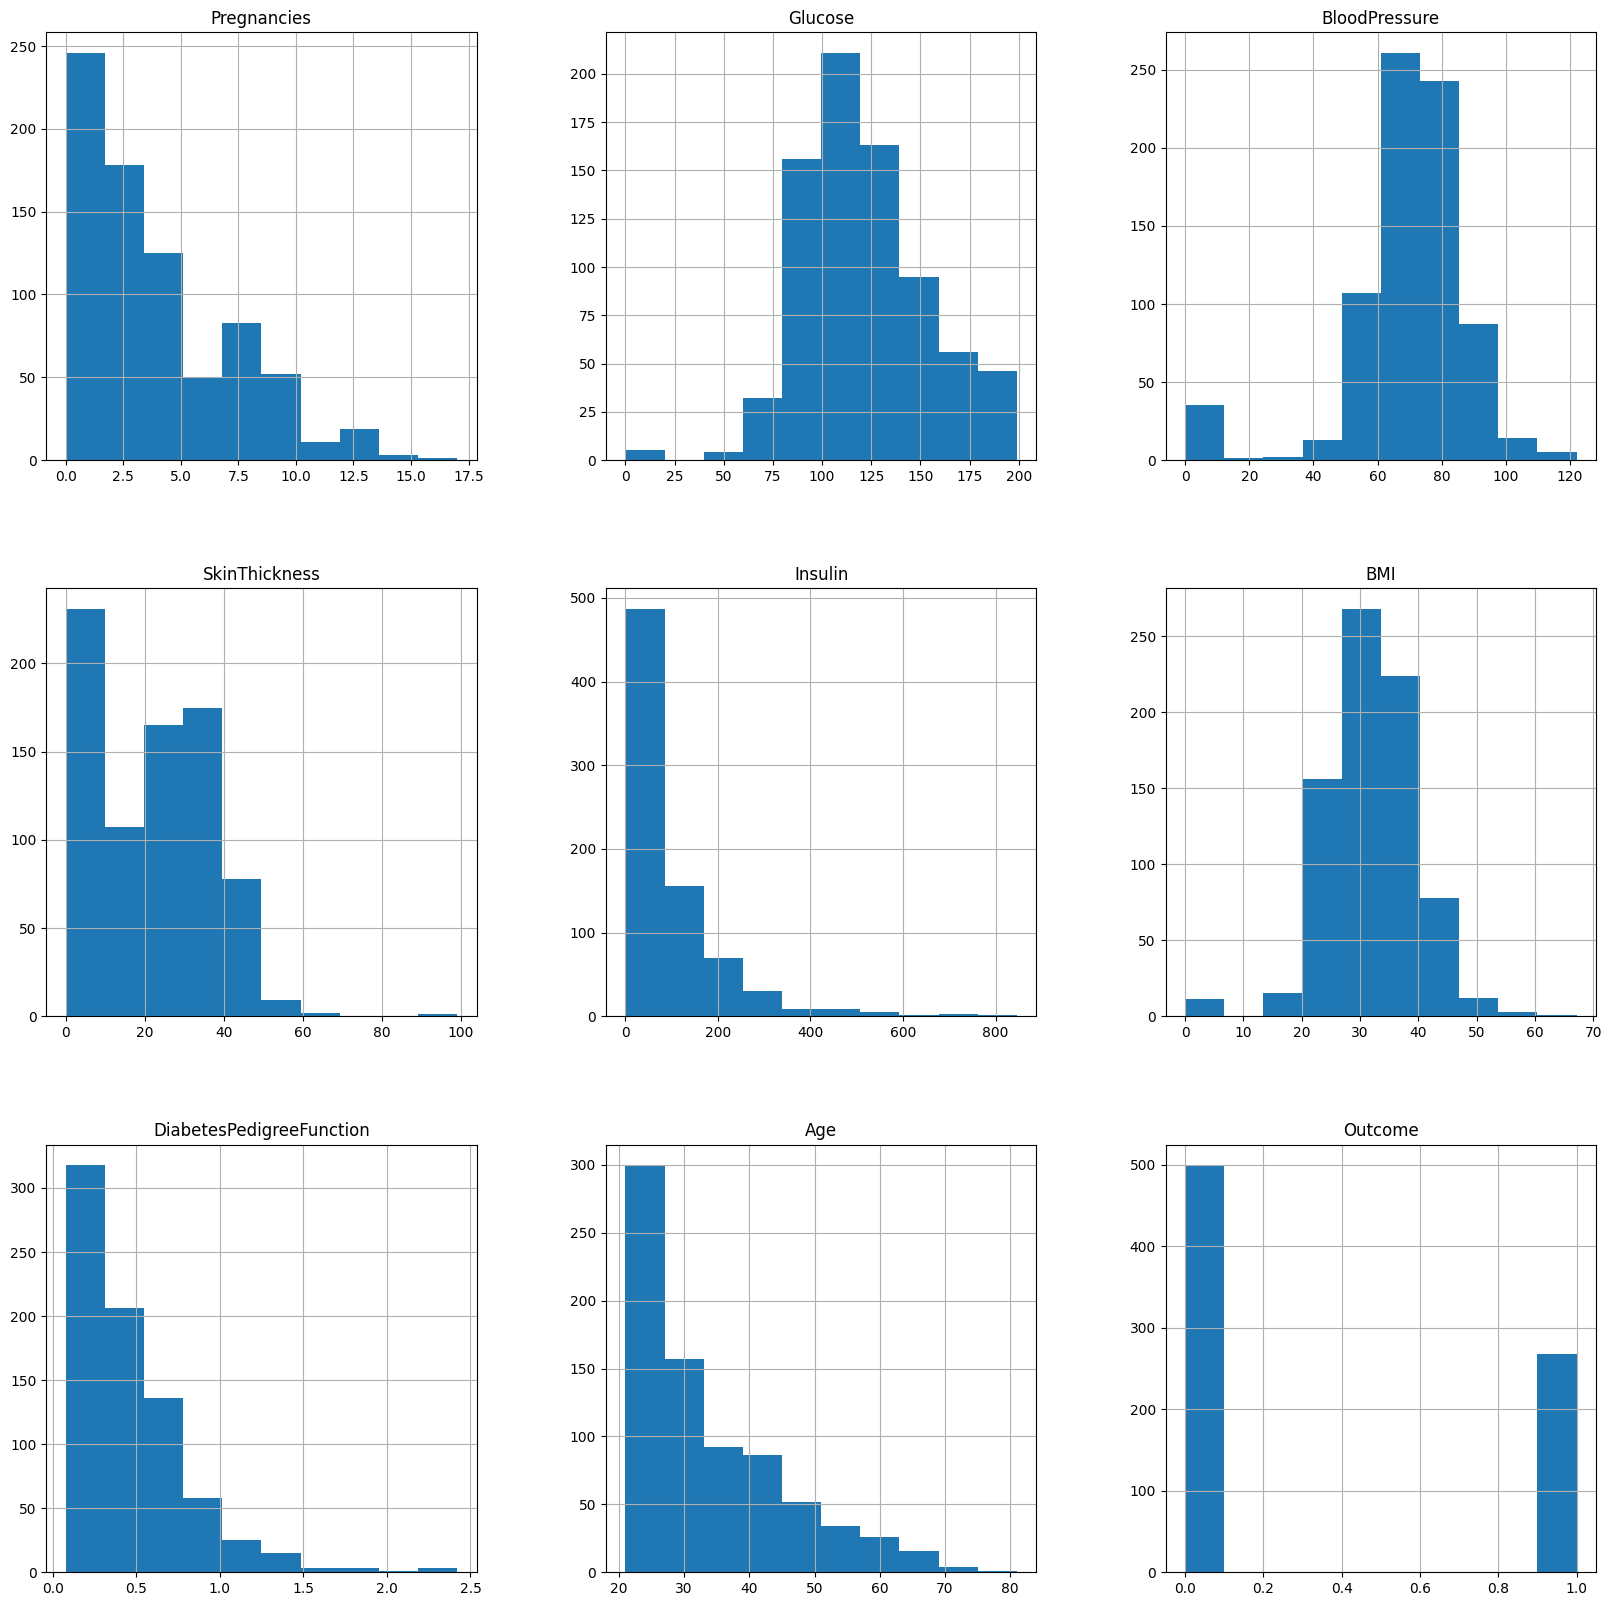

In [ ]:
p = data.hist(figsize = (20,20))

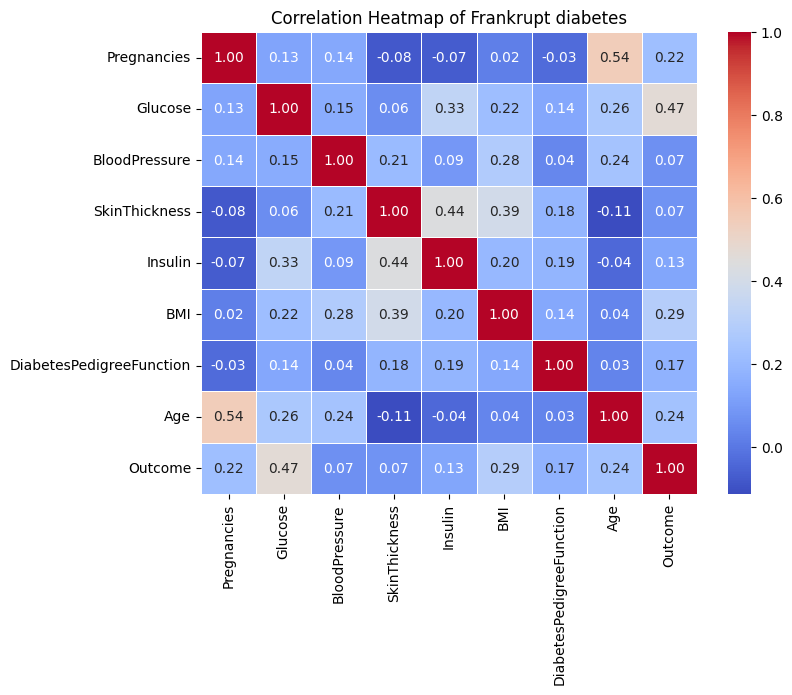

In [ ]:
# Calculating correlation matrix
correlation_matrix = data.corr()

# Plotting correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of PIMA diabetes')
plt.show()

In [ ]:
# Normalisation
sc_X = StandardScaler()
X =  pd.DataFrame(sc_X.fit_transform(data.drop(["Outcome"],axis = 1),),
        columns=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'])
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639947,0.848324,0.149641,0.907270,-0.692891,0.204013,0.468492,1.425995
1,-0.844885,-1.123396,-0.160546,0.530902,-0.692891,-0.684422,-0.365061,-0.190672
2,1.233880,1.943724,-0.263941,-1.288212,-0.692891,-1.103255,0.604397,-0.105584
3,-0.844885,-0.998208,-0.160546,0.154533,0.123302,-0.494043,-0.920763,-1.041549
4,-1.141852,0.504055,-1.504687,0.907270,0.765836,1.409746,5.484909,-0.020496


In [ ]:
y=data.Outcome

# **Random Forest**

In [ ]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
rf_model = RandomForestClassifier().fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("The accuracy of random forest model is :", accuracy)

The accuracy of random forest model is : 0.7402597402597403


In [ ]:
# classification report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.80      0.80       151
           1       0.62      0.62      0.62        80

    accuracy                           0.74       231
   macro avg       0.71      0.71      0.71       231
weighted avg       0.74      0.74      0.74       231



In [ ]:
# parameter grid for Random Forest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize the Random Forest classifier
rf = RandomForestClassifier()

# Initialize GridSearchCV with the Random Forest classifier and parameter grid
grid_search_rf = GridSearchCV(rf, param_grid_rf, cv=5, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search_rf.fit(X_train, y_train)

# best parameters found by GridSearchCV for Random Forest
best_params_rf = grid_search_rf.best_params_
print("Best Parameters for Random Forest:", best_params_rf)

# best cross-validation score found by GridSearchCV for Random Forest
best_score_rf = grid_search_rf.best_score_
print("Best Cross-Validation Score for Random Forest:", best_score_rf)

# best Random Forest model found by GridSearchCV
best_rf = grid_search_rf.best_estimator_

# predictions on the test data using the best Random Forest model
y_pred_rf = best_rf.predict(X_test)

# classification report for Random Forest
report_rf = classification_report(y_test, y_pred_rf)
print("Classification Report for Random Forest:")
print(report_rf)

Best Parameters for Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross-Validation Score for Random Forest: 0.7839217722395292
Classification Report for Random Forest:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       151
           1       0.65      0.64      0.64        80

    accuracy                           0.75       231
   macro avg       0.73      0.73      0.73       231
weighted avg       0.75      0.75      0.75       231



# **Support Vector Machine (SVM)**

In [ ]:
# Create an SVM classifier with a linear kernel
clf2= SVC(kernel='linear')
clf2.fit(X_train,y_train)
pred2 =clf2.predict(X_test)
accuracy_score(y_test,pred2)

# classification report
print(classification_report(y_test, pred2))

              precision    recall  f1-score   support

           0       0.80      0.81      0.81       151
           1       0.64      0.62      0.63        80

    accuracy                           0.75       231
   macro avg       0.72      0.72      0.72       231
weighted avg       0.75      0.75      0.75       231



In [ ]:
# Define a parameter grid for SVM
param_grid_svm = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [1, 0.1, 0.01, 0.001],  # Kernel coefficient
    'kernel': ['rbf', 'linear']  # Kernel type
}

# Initialize the SVM classifier
svm = SVC()

# Initialize GridSearchCV with the SVM classifier and parameter grid
grid_search_svm = GridSearchCV(svm, param_grid_svm, cv=5, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search_svm.fit(X_train, y_train)

# best parameters found by GridSearchCV for SVM
best_params_svm = grid_search_svm.best_params_
print("Best Parameters for SVM:", best_params_svm)

# best cross-validation score found by GridSearchCV for SVM
best_score_svm = grid_search_svm.best_score_
print("Best Cross-Validation Score for SVM:", best_score_svm)

# best SVM model found by GridSearchCV
best_svm = grid_search_svm.best_estimator_

# predictions on the test data using the best SVM model
y_pred_svm = best_svm.predict(X_test)

# classification report for SVM
report_svm = classification_report(y_test, y_pred_svm)
print("Classification Report for SVM:")
print(report_svm)


Best Parameters for SVM: {'C': 1, 'gamma': 1, 'kernel': 'linear'}
Best Cross-Validation Score for SVM: 0.7839217722395293
Classification Report for SVM:
              precision    recall  f1-score   support

           0       0.80      0.81      0.81       151
           1       0.64      0.62      0.63        80

    accuracy                           0.75       231
   macro avg       0.72      0.72      0.72       231
weighted avg       0.75      0.75      0.75       231



# **K-Nearest Neighbors Algorithm (KNN)**

In [ ]:
# Initialize the KNN classifier with n_neighbors=2
knn = KNeighborsClassifier(n_neighbors=2)

# Fit the KNN classifier on the training data
knn.fit(X_train, y_train)

# Make predictions on the test data
y_pred = knn.predict(X_test)

# Generate a classification report
report = classification_report(y_test, y_pred)

# Print the classification report
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.89      0.78       151
           1       0.56      0.25      0.34        80

    accuracy                           0.67       231
   macro avg       0.62      0.57      0.56       231
weighted avg       0.64      0.67      0.63       231



In [ ]:
# Define a parameter grid
param_grid = {
    'n_neighbors': range(1, 50),
    'weights': ['uniform', 'distance'],  # Weighting of neighbors
    'metric': ['euclidean', 'manhattan']  # Distance metric
}

# Initialize the KNN classifier
knn = KNeighborsClassifier()

# Initialize GridSearchCV with the KNN classifier and parameter grid
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# best parameters found by GridSearchCV
best_params = grid_search.best_params_
print("Best Parameters:", best_params)

# best cross-validation score found by GridSearchCV
best_score = grid_search.best_score_
print("Best Cross-Validation Score:", best_score)

# best KNN model found by GridSearchCV
best_knn = grid_search.best_estimator_

# predictions on the test data using the best KNN model
y_pred = best_knn.predict(X_test)

# Print the classification report
report = classification_report(y_test, y_pred)
print("Classification Report:")
print(report)

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 13, 'weights': 'distance'}
Best Cross-Validation Score: 0.7784181377639321
Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.83      0.78       151
           1       0.59      0.46      0.52        80

    accuracy                           0.70       231
   macro avg       0.67      0.65      0.65       231
weighted avg       0.69      0.70      0.69       231



# **Hybrid Approach**

# Combine the best performing Random Forest, SVM, and KNN models into a hybrid model and evaluate its performance.

Make predictions using the best models and combine them using a majority vote.



In [ ]:
# Make predictions on the test set using the best Random Forest model
y_pred_rf_best = best_rf.predict(X_test)

# Make predictions on the test set using the best SVM model
y_pred_svm_best = best_svm.predict(X_test)

# Make predictions on the test set using the best KNN model
y_pred_knn_best = best_knn.predict(X_test)

# Combine the predictions using a majority vote
y_pred_hybrid = (y_pred_rf_best + y_pred_svm_best + y_pred_knn_best >= 2).astype(int)

## Evaluate hybrid model



Evaluate the performance of the hybrid model using accuracy and classification report.



In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate the accuracy of the hybrid model
accuracy_hybrid = accuracy_score(y_test, y_pred_hybrid)
print("Hybrid Model Accuracy:", accuracy_hybrid)

# Print the classification report for the hybrid model
report_hybrid = classification_report(y_test, y_pred_hybrid)
print("Classification Report for Hybrid Model:")
print(report_hybrid)

Hybrid Model Accuracy: 0.7489177489177489
Classification Report for Hybrid Model:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       151
           1       0.64      0.61      0.63        80

    accuracy                           0.75       231
   macro avg       0.72      0.72      0.72       231
weighted avg       0.75      0.75      0.75       231

